# Homework 6 – Problem 1: PCA with an Undercomplete Linear Autoencoder

**Hussein Jawad**

The plots of training data on slides 24 and 28 come from another example. Here we generate a
new 3D training set with the provided `generate_3d_data()` function, train the linear
autoencoder from slide 25 on it, and produce our own versions of the two plots:

* **slide 24:** the 3D training data, drawn with `scatter()` from `Axes3D`, and
* **slide 28:** the 2D `codings` output by the encoder (first hidden layer).

The code follows the structure of the PyTorch Lab 6 notebook (section *Simple Autoencoder – PCA &
Dimensionality Reduction*), with a few tweaks noted where they occur.

# Google Colab setup

Mount Google Drive so that the saved figures persist between Colab sessions.
(When the notebook is run outside Colab, the current folder is used instead.)

In [1]:
# %pip install torch matplotlib scikit-learn  # Uncomment once if the packages are missing.

import sys                                              # Access to the list of loaded modules.
from pathlib import Path                                # Path builds file paths that work on any OS.

IS_COLAB = "google.colab" in sys.modules                # True when running inside Google Colab.
if IS_COLAB:                                            # Only Colab can mount Google Drive.
    from google.colab import drive                      # Colab tool to connect your Google Drive.
    drive.mount('/content/drive')                       # Mount Google Drive (asks for permission the first time).
    # Permanent location in Google Drive: figures are kept here between Colab sessions.
    PROJECT_DIR = Path('/content/drive/MyDrive/CSCI-E-89-1-Deep-Learning/HW06')  # Project folder inside your Drive.
else:                                                   # Running locally (e.g., Jupyter on a laptop).
    PROJECT_DIR = Path.cwd()                            # Use the notebook's current folder.
PROJECT_DIR.mkdir(parents=True, exist_ok=True)          # Create the folder; no error if it already exists.
print('Project folder:', PROJECT_DIR)                   # Show where outputs will be saved.

Project folder: /home/user/e89_Hussein_Jawad_HW06


# Setup (PyTorch)

Same setup as the lab, keeping only what Problem 1 needs (no image datasets).

In [2]:
import os                                               # Operating-system utilities (folders, paths).
import numpy as np                                      # Numerical arrays.
import torch                                            # PyTorch: tensors and automatic differentiation.
from torch import nn                                    # Neural network layers and loss functions.
from torch.utils.data import DataLoader, TensorDataset  # Mini-batching utilities.
import matplotlib as mpl                                # Matplotlib configuration (rc settings).
import matplotlib.pyplot as plt                         # Plotting library.

np.random.seed(42)                                      # Reproducible NumPy randomness.
torch.manual_seed(42)                                   # Reproducible PyTorch randomness.

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # Use the GPU if available.
print(f"PyTorch {torch.__version__}; device: {device}")  # Show the PyTorch version and device.

mpl.rc('axes', labelsize=14)                            # Axis label font size.
mpl.rc('xtick', labelsize=12)                           # x-tick label font size.
mpl.rc('ytick', labelsize=12)                           # y-tick label font size.

IMAGES_PATH = os.path.join(PROJECT_DIR, "images", "autoencoders")  # Folder for saved figures.
os.makedirs(IMAGES_PATH, exist_ok=True)                 # Create it if needed.

PyTorch 2.14.1+cu130; device: cpu


Helper functions from the lab: saving figures, converting data to tensors, and batched inference.

In [3]:
def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    if tight_layout:                                    # Optionally remove extra white space.
        plt.tight_layout()                              # Adjust subplot spacing.
    plt.savefig(os.path.join(IMAGES_PATH, fig_id + "." + fig_extension),
                format=fig_extension, dpi=resolution)   # Save the current figure to IMAGES_PATH.

def as_tensor(data):
    return torch.as_tensor(data, dtype=torch.float32).detach().cpu()  # NumPy/tensor -> float32 CPU tensor.

def predict(model, data, batch_size=256):
    """Batched inference; return NumPy arrays (including tuple outputs)."""
    was_training = model.training                       # Remember the model's current mode.
    model.eval()                                        # Switch to evaluation mode.
    model_device = next(model.parameters()).device      # Device where the model's weights live.
    batches = []                                        # Collect the outputs of each batch.
    try:
        with torch.inference_mode():                    # No gradient tracking during inference.
            for (batch,) in DataLoader(TensorDataset(as_tensor(data)), batch_size=batch_size):  # Loop over batches.
                result = model(batch.to(model_device))  # Forward pass on the model's device.
                batches.append(tuple(v.cpu() for v in result) if isinstance(result, tuple)
                               else result.cpu())       # Store outputs on the CPU.
    finally:
        model.train(was_training)                       # Restore the original mode.
    if isinstance(batches[0], tuple):                   # Models with several outputs:
        return tuple(torch.cat(parts).numpy() for parts in zip(*batches))  # concatenate each output.
    return torch.cat(batches).numpy()                   # Concatenate all batches into one NumPy array.

The lab's `train_autoencoder()` function. Tweaks for this problem: the `rounded_accuracy`
option is removed (it is meant for images, and we only track the MSE), and a `print_every`
argument is added so long training runs do not print every epoch.

In [4]:
def train_autoencoder(model, data, optimizer, criterion, epochs, validation_data=None,
                      batch_size=32, print_every=1):
    """The inputs are also the targets: the model learns to reconstruct them."""
    model.to(device)                                    # Move the model to the device.
    train_loader = DataLoader(TensorDataset(as_tensor(data)), batch_size=batch_size, shuffle=True)  # Shuffled mini-batches.
    valid_loader = (DataLoader(TensorDataset(as_tensor(validation_data)), batch_size=batch_size)
                    if validation_data is not None else None)  # Optional validation batches.
    history = {}                                        # Per-epoch metrics.
    for epoch in range(epochs):                         # Loop over the epochs.
        logs = {}                                       # Metrics for this epoch.
        for training, loader in [(True, train_loader), (False, valid_loader)]:  # Training pass, then validation pass.
            if loader is None:                          # No validation data given:
                continue                                # skip the validation pass.
            model.train(training)                       # Set training or evaluation mode.
            loss_sum = count = 0                        # Running totals for the mean loss.
            with torch.set_grad_enabled(training):      # Gradients only during training.
                for (clean,) in loader:                 # Loop over mini-batches.
                    clean = clean.to(device)            # Move the batch to the device.
                    if training:
                        optimizer.zero_grad(set_to_none=True)  # Reset the gradients.
                    reconstructed = model(clean)        # Forward pass: reconstruct the inputs.
                    loss = criterion(reconstructed, clean)  # Reconstruction loss vs. the inputs.
                    if training:
                        loss.backward()                 # Backpropagation.
                        optimizer.step()                # Update the weights.
                    count += len(clean)                 # Number of instances seen.
                    loss_sum += loss.item() * len(clean)  # Weighted sum of the batch losses.
            prefix = "" if training else "val_"         # Name prefix for validation metrics.
            logs[prefix + "loss"] = loss_sum / count    # Mean loss over the epoch.
        for key, value in logs.items():                 # Append this epoch's metrics...
            history.setdefault(key, []).append(value)   # ...to the history dictionary.
        if (epoch + 1) % print_every == 0:              # Print only every `print_every` epochs.
            print(f"Epoch {epoch + 1}/{epochs}: " + ", ".join(f"{k}={v:.4f}" for k, v in logs.items()))
    model.eval()                                        # Leave the model in evaluation mode.
    return history                                      # Return the learning curves.

# Simple Autoencoder – PCA & Dimensionality Reduction

The encoder and the decoder are each a single `nn.Linear` layer, and the autoencoder is a
`Sequential` model containing the encoder followed by the decoder (slide 25). It has 3 inputs,
a 2D coding layer, and 3 outputs. To perform PCA we use **no activation function** (all neurons
are linear) and the **MSE** cost function.

In [5]:
torch.manual_seed(42)                                   # Reproducible weight initialization (slide 25).
encoder = nn.Linear(3, 2)                               # Encoder: 3D inputs -> 2D codings.
decoder = nn.Linear(2, 3)                               # Decoder: 2D codings -> 3D reconstructions.
autoencoder = nn.Sequential(encoder, decoder).to(device)  # Chain encoder and decoder; move to device.
optimizer = torch.optim.NAdam(autoencoder.parameters(), lr=0.02)  # NAdam (Géron's optimizer) converges much faster than SGD.

## Build the 3D dataset (code given in Problem 1)

In [6]:
np.random.seed(4)                                       # Reproducible dataset.

def generate_3d_data(m, w1=0.1, w2=0.3, noise=0.1):
    angles = np.random.rand(m) * 3 * np.pi / 2 - 0.5    # Random angles in [-0.5, 3π/2 - 0.5).
    data = np.empty((m, 3))                             # Allocate an m x 3 array.
    data[:, 0] = np.cos(angles) + np.sin(angles)/2 + noise * np.random.randn(m) / 2  # x1: curved + noise.
    data[:, 1] = np.sin(angles) * 0.7 + noise * np.random.randn(m) / 2  # x2: curved + noise.
    data[:, 2] = data[:, 0] * w1 + data[:, 1] * w2 + noise * np.random.randn(m)  # x3: near plane w1*x1 + w2*x2.
    return data                                         # Return the 3D dataset.

X_train = generate_3d_data(60)                          # 60 training instances.
X_train = X_train - X_train.mean(axis=0, keepdims=0)    # Center the data (PCA assumes centered data).
print(X_train[:2])                                      # Peek at the first two instances.
X_train.shape                                           # (60, 3): 60 vectors of dimension 3.

[[-1.03976771 -0.76023846 -0.33288048]
 [-0.03178419  0.39026057 -0.03647667]]


(60, 3)

## Visualize the data (slide 24)

To visualize 3D data we use the `scatter()` function from the `Axes3D` package:

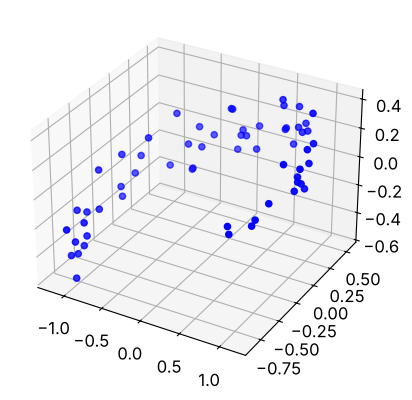

In [7]:
%matplotlib inline
from mpl_toolkits.mplot3d import Axes3D                 # Registers the '3d' projection.
fig = plt.figure()                                      # New figure.
ax = fig.add_subplot(111, projection='3d')              # 3D axes.
ax.scatter(X_train[:, 0], X_train[:, 1], X_train[:, 2], c='b', marker='o')  # Blue dot per instance.
save_fig("problem1_3d_training_data", tight_layout=False)  # Save the figure (to Drive in Colab).
plt.show()                                              # Display the figure.

## Train the autoencoder

The same dataset, `X_train`, is used as both the inputs and the targets.

**Tweaks:** the optimizer is NAdam (as in Géron's notebook) instead of the lab's SGD. With SGD
(lr=0.1) the loss stays on a plateau for about 200 epochs and needs 300–400 epochs to converge;
NAdam reaches the PCA optimum in about 40 epochs. We use lr=0.02 rather than Géron's lr=0.2,
because his `train()` uses a learning-rate scheduler and gradient clipping to tame the large
rate, while the lab's `train_autoencoder()` does not (with lr=0.2 the loss keeps bouncing).
We train for 100 epochs (instead of the lab's 5) and print every 10.

In [8]:
history = train_autoencoder(autoencoder, X_train, optimizer, nn.MSELoss(),
                            epochs=100, print_every=10)  # Train 100 epochs; print every 10.

Epoch 10/100: loss=0.0760
Epoch 20/100: loss=0.0428
Epoch 30/100: loss=0.0118
Epoch 40/100: loss=0.0036
Epoch 50/100: loss=0.0035
Epoch 60/100: loss=0.0035
Epoch 70/100: loss=0.0034
Epoch 80/100: loss=0.0035
Epoch 90/100: loss=0.0034
Epoch 100/100: loss=0.0036


Learning curve (log scale), showing the convergence:

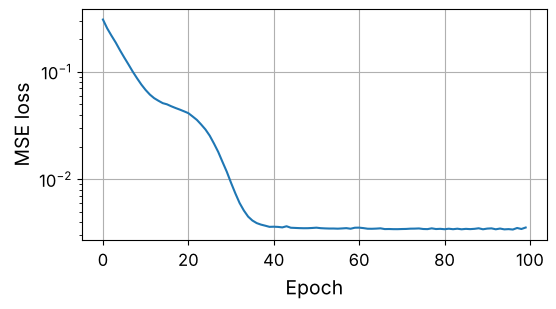

In [9]:
plt.figure(figsize=(6, 3))                              # New figure.
plt.semilogy(history["loss"])                           # Training loss per epoch, log scale.
plt.xlabel("Epoch")                                     # x-axis label.
plt.ylabel("MSE loss")                                  # y-axis label.
plt.grid(True)                                          # Add a grid.
plt.show()                                              # Display the figure.

## `codings`, outputs of the first hidden layer (slide 28)

No `Linear` layer is followed by a non-linear unit. We trained with 60 vectors of dimension 3,
so the encoder (first hidden layer) produces 60 vectors of dimension 2 (`codings`):

In [10]:
codings = predict(encoder, X_train)                     # Run only the encoder: 3D -> 2D.
print(codings[:2])                                      # Peek at the first two codings.
codings.shape                                           # (60, 2): 60 vectors of dimension 2.

[[-1.4575241   0.72574306]
 [-0.47720015 -0.10005134]]


(60, 2)

Vectors collected in `codings` all have two dimensions. Plot them in 2D:

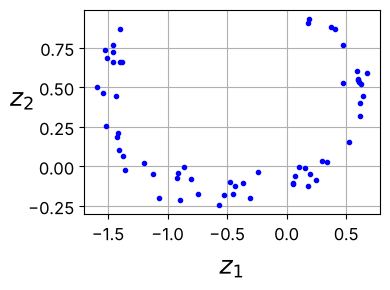

In [11]:
fig = plt.figure(figsize=(4, 3))                        # New figure.
plt.plot(codings[:, 0], codings[:, 1], "b.")            # Blue dot per coding.
plt.xlabel("$z_1$", fontsize=18)                        # First coding dimension.
plt.ylabel("$z_2$", fontsize=18, rotation=0)            # Second coding dimension.
plt.grid(True)                                          # Add a grid.
save_fig("linear_autoencoder_pca_plot")                 # Save the figure (to Drive in Colab).
plt.show()                                              # Display the figure.

## Check: is this really PCA?

The best possible linear 2D reconstruction is the PCA one, so the autoencoder's reconstruction
error should match it:

In [12]:
from sklearn.decomposition import PCA                   # Scikit-Learn's PCA.

pca = PCA(n_components=2)                               # Project onto the top 2 principal components.
X_pca_rec = pca.inverse_transform(pca.fit_transform(X_train))  # Project to 2D, then back to 3D.
X_ae_rec = predict(autoencoder, X_train)                # Autoencoder reconstructions.
print(f"PCA reconstruction MSE:         {np.mean((X_train - X_pca_rec) ** 2):.5f}")  # Optimal linear error.
print(f"Autoencoder reconstruction MSE: {np.mean((X_train - X_ae_rec) ** 2):.5f}")   # Should be nearly equal.

PCA reconstruction MSE:         0.00339
Autoencoder reconstruction MSE: 0.00342


**Observation:** the 3D training data lies close to the plane $x_3 \approx 0.1x_1 + 0.3x_2$, curved
into an arc. The 2D codings keep that arc shape and drop only the low-variance direction (mostly
the noise off the plane). The autoencoder's reconstruction error matches PCA's, so it found the
best 2D plane to project the data onto: the plane that keeps the largest variance. Its coding
axes $z_1, z_2$ need not be the principal components themselves (they can be rotated, scaled
or skewed within that plane), which is why the arc may look rotated or stretched compared with
a PCA plot.